<a href="https://colab.research.google.com/github/elena-gazzini/2026_Intro_Python/blob/main/EG_1_3_numpy_environmental_exercises.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

> Notebook-friendly copy of `part-I/1.3-numpy-environmental-exercises.ipynb`, generated by `tools/make_live.py`. Edit the book notebook, not this file.

In [16]:
# --- environment setup (generated, not part of the lesson) ---
# Colab and Kaggle do not ship every package this notebook imports.
# This is a no-op in an environment that is already set up.
import importlib.util
import subprocess
import sys

for module, package in {"gsw": "gsw", "pooch": "pooch"}.items():
    if importlib.util.find_spec(module) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", package], check=True)

# Environmental Exercises

**ℹ️ How to use these exercises**

Attempt each from scratch in the empty code cell. Import numpy as `np`, and encode units in your variable names.

## Exercise 1: Ocean float profiles

<em>One cycle of an Argo float: deployment, descent to a drifting depth of about 1000 m, ten days of
drift, a dive to the profiling depth, then the ascent during which the measurements are taken, and
transmission to satellite at the surface before the next cycle begins. The panel on the right shows
what one ascent produces — the temperature and salinity profiles you are about to work with.
Illustration &copy; Thomas Haessig, from
<a href="https://www.euro-argo.eu/Outreach/Educational-material/Discover-Argo-floats-for-kids/How-do-the-Argo-floats-fulfill-their-mission-in-the-Ocean">Euro-Argo ERIC's educational material</a>.</em>


[Argo](https://argo.ucsd.edu/) floats are autonomous instruments that drift with ocean currents,
periodically diving and surfacing while recording temperature, salinity, and pressure. Each dive
produces one *profile*: a set of measurements at many depth *levels*, with a single latitude,
longitude, and date attached.

This exercise uses real Argo data. Steps 1 to 8 use only what 1.1 to 1.3 cover: loading
arrays, inspecting shapes, rebuilding an axis, vectorised arithmetic, reductions along an axis,
boolean masks, and NaN-aware statistics. Steps 9 to 11 then plot what you computed.

**ℹ️ Beyond this subchapter**

Steps 9 to 11 use `matplotlib`, which gets its own treatment in 1.4. Import it once with
`import matplotlib.pyplot as plt`; after that you need only the functions below, and each is
named again where it is wanted:

- `plt.figure()` — start a new, empty figure; without it, every plot in a cell lands on the
  same axes
- [`plt.plot`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.plot.html) — a line, or
  one line per column when handed a 2D array
- [`plt.errorbar`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.errorbar.html) — a
  line with error bars
- [`plt.scatter`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.scatter.html) — points
- `plt.xlabel`, `plt.ylabel`, `plt.title` — each takes a string
- `plt.show()` — draw the current figure

An array of numbers with no picture attached is hard to sanity-check, which is why these three
steps sit here rather than waiting for 1.4: the profiles are the fastest way to see whether Steps 4
to 6 produced something physical.

In [1]:
# Pre-supplied: download and unzip the Argo data files.
import pooch

files = pooch.retrieve(
    url="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/data/part-I/argo_float_data.zip",
    known_hash="sha256:dd913ba3450241bcd5d5697187ea68d398bdd7fd563a04cc74386834749c25f5",
    processor=pooch.Unzip(),
    path=pooch.os_cache("mlees"),
)
for f in sorted(files):
    print(f)

Unzipping contents of '/root/.cache/mlees/3447957d2e428811e6534de5c131c0db-argo_float_data.zip' to '/root/.cache/mlees/3447957d2e428811e6534de5c131c0db-argo_float_data.zip.unzip'


/root/.cache/mlees/3447957d2e428811e6534de5c131c0db-argo_float_data.zip.unzip/P.npy
/root/.cache/mlees/3447957d2e428811e6534de5c131c0db-argo_float_data.zip.unzip/S.npy
/root/.cache/mlees/3447957d2e428811e6534de5c131c0db-argo_float_data.zip.unzip/T.npy
/root/.cache/mlees/3447957d2e428811e6534de5c131c0db-argo_float_data.zip.unzip/date.npy
/root/.cache/mlees/3447957d2e428811e6534de5c131c0db-argo_float_data.zip.unzip/lat.npy
/root/.cache/mlees/3447957d2e428811e6534de5c131c0db-argo_float_data.zip.unzip/levels.npy
/root/.cache/mlees/3447957d2e428811e6534de5c131c0db-argo_float_data.zip.unzip/lon.npy


**Step 1.** Load each `.npy` file into a numpy array with `np.load`. Name them `T` (temperature,
°C), `S` (practical salinity, unitless), `P` (pressure, dbar), `date`, `lat`, `lon`, and `level` (depth level).

Read the filenames printed above to work out which file is which.

In [6]:
from pathlib import Path
# Your solution here
# Hint: every file sits in the same folder, Path(files[0]).parent (Path comes from pathlib)
# Hint: join a filename onto that folder with /, as in Path("_files") / "station_daily.csv"
# Hint: np.load(path) returns the array stored in a .npy file
import numpy as np
from pathlib import Path

# find the folder containing the downloaded files
folder = Path(files[0]).parent

# loads the data from each .npy file into an array.
T = np.load(folder / "T.npy")
S = np.load(folder / "S.npy")
P = np.load(folder / "P.npy")
date = np.load(folder / "date.npy")
lat = np.load(folder / "lat.npy")
lon = np.load(folder / "lon.npy")
level = np.load(folder / "levels.npy")
# attention c'était noté levels au pluriel à l'étape d'avant...
# /root/.cache/mlees/3447957d2e428811e6534de5c131c0db-argo_float_data.zip.unzip/levels.npy


**Step 2.** Print the `shape` of every array you loaded. Then answer in a comment: which
dimension do `T`, `S`, and `P` share with `level`, and which do they share with `lat`, `lon`,
and `date`?

In [7]:
# Your solution here
# Hint: the profile arrays are two-dimensional; the coordinate arrays are one-dimensional
# Hint: a 2D array's shape tells you the length of each axis — match those against the 1D shapes
print("T:", T.shape)
print("S:", S.shape)
print("P:", P.shape)
print("date:", date.shape)
print("lat:", lat.shape)
print("lon:", lon.shape)
print("level:", level.shape)



T: (78, 75)
S: (78, 75)
P: (78, 75)
date: (75,)
lat: (75,)
lon: (75,)
level: (78,)


Results:

- T, S, P have shape (78, 75): 78 rows (axis 0) and 75 columns (axis 1).

- level has shape (78,): 78 depth levels.

- date, lat, lon each have shape (75,): 75 profiles.

axis 0 corresponds to depth levels, and axis 1 corresponds to individual profiles in your data.

So:

- T, S, P - axis 0 (78) matches `levels` (78) because they correspond to depth levels.

- T, S, P - axis 1 (75) matches `date`, `lat`, `lon` (75) because they correspond to profiles.

We have 75 ocean profiles, and each profile contains measurements at 78 depth levels.

**Step 3.** The `level` array is a regular sequence. Recreate it twice — once with `np.arange`
and once with `np.linspace` — and confirm each matches the original using `np.allclose`.

Read `level[0]`, `level[-1]`, and `level.size` first to work out the arguments.

In [12]:
# Your solution here
# Hint: np.arange(start, stop, step) excludes the stop value
# Hint: np.linspace(start, stop, num) includes both ends
# Hint: np.allclose(a, b) returns True when every pair of elements is close enough

# first inspect the array
print(level[0])             # the first value
print(level[-1])            # the last value
print(level.size)    # the number of values (78)

# recreate the level array using arange
level_ar = np.arange(level[0], level[-1] + 1, 1)
# creates a sequence with a fixed step. The stop value is excluded, so we add 1

# recreate the level array using linspace
level_ls = np.linspace(level[0], level[-1], level.size)
# creates a sequence with a specified number of values, including both endpoints.

# check if they match the original
print(np.allclose(level_ar, level))
print(np.allclose(level_ls, level))
# checks whether the recreated array matches the original.
# both True so they recreations match the original

0
77
78
True
True


**Step 4.** Compute the density of seawater relative to pure water, in kg m⁻³:

$$\rho - \rho_{\text{pure water}} = a\,S + b\,\Theta + c\,\Theta^{2}$$

where $S$ is salinity and $\Theta$ is the *conservative* temperature, computed from
temperature, salinity, and pressure by the `gsw` library. The constants are

```python
a = 7.718e-1
b = -8.44e-2
c = -4.561e-3
```

The cell below imports the function. Compute `conservative_temp` and `relative_density`, print
the shape of your result, and check it matches `T`.

Both `CT_from_t` and the formula expect *absolute* salinity, in g/kg, while Argo reports
*practical* salinity, which has no unit. Absolute salinity is about 0.5 % larger; for these
profiles, using practical salinity in its place lowers every relative density by about
0.13 kg m⁻³, which is small enough to ignore here. `gsw.SA_from_SP` does the exact conversion
when it matters.

Source: Roquet et al. (2015), *J. Phys. Oceanogr.* 45, 2564–2579, and the
[TEOS-10 GSW toolbox](https://www.teos-10.org/).

In [19]:
# Pre-supplied: the conservative-temperature function from the gsw library
from gsw import CT_from_t

# attention bien runner the tout premier chunck de code sinon il ne marche pas

In [21]:
# Your solution here
# Hint: CT_from_t(SA, t, p) takes salinity, temperature, and pressure — in that order
# Hint: the whole formula is one vectorised expression; no loop is needed
# Hint: Theta**2 squares every element

# loads the seawater science library
import gsw

# calculate the conservative tempature
conservative_temp = gsw.CT_from_t(S, T, P)
# calculates conservative temperature using salinity, temperature, and pressure

# constants
a = 7.718e-1
b = -8.44e-2
c = -4.561e-3

# caculate relative density (density difference relative to pure water)
relative_density = a*S + b*conservative_temp + c*conservative_temp**2

# print the shape and check it matches T
print(relative_density.shape)
# .shape: shows the dimensions of the result
print(np.allclose(relative_density.shape, T.shape))
# checks whether values are numerically close. Here, we should use it to compare the arrays themselves, not their shapes.

(78, 75)
True


**Step 5.** Compute the mean and the standard deviation of `T`, `S`, `P`, and
`relative_density` **at each depth**, averaging across all the profiles.

Check your result has the same shape as `level` — if it does not, you reduced along the wrong
axis.

***The key rule***

- `axis = 0` averages down the rows, combining depth levels and keeping the profiles.

- `axis = 1` averages across the columns, combining profiles and keeping the depth levels.

Therefore, for Step 5, we need `axis = 1`, because we want one mean per depth level.

In [25]:
# Your solution here
# Hint: pick the axis that runs across profiles, not across depths
# Hint: mean_T.shape should equal level.shape

# mean at each depth (averaging across profiles)
mean_T = np.mean(T, axis = 1)
mean_S = np.mean(S, axis = 1)
mean_P = np.mean(P, axis = 1)
mean_relative_density = np.mean(relative_density, axis = 1)

# standard deviation at each depth (averaging across profiles)
std_T = np.std(T, axis = 1)
std_S = np.std(S, axis = 1)
std_P = np.std(P, axis = 1)
std_relative_density = np.std(relative_density, axis = 1)

# check the shapes
print(np.allclose(mean_T.shape, level.shape))
print(np.allclose(std_T.shape, level.shape))
print(np.allclose(mean_S.shape, level.shape))
print(np.allclose(std_S.shape, level.shape))
print(np.allclose(mean_P.shape, level.shape))
print(np.allclose(std_P.shape, level.shape))
print(np.allclose(mean_relative_density.shape, level.shape))
print(np.allclose(std_relative_density.shape, level.shape))

# great they are all the same size

True
True
True
True
True
True
True
True


- `np.mean(...)` calculates the average.

- `np.std(...)` calculates the standard deviation, which tells you how much the measurements vary

**Step 6.** Look at the mean you just computed. Many entries are `nan`, because Argo profiles
contain missing values and an ordinary mean propagates them.

1. Count how many values in `T` are missing, using `np.isnan` and a sum over the boolean mask.
2. Express that as a percentage of all values in `T`.
3. Recompute the mean and standard deviation with `np.nanmean` and `np.nanstd`, and confirm no
   `nan` remains.

In [30]:
# Your solution here
# Hint: np.isnan(T) gives a boolean array; True counts as 1 when summed
# Hint: T.size is the total number of elements
# Hint: np.isnan(result).sum() counts the nan that survived; it should be 0

# 1. count missing temperature values
missing = np.isnan(T).sum()
print("Missing T values:", missing)

# 2. calculate the % of missing T values
percentage = missing / T.size * 100
print("Percentage of missing T values:", percentage, "%")

# 3. recalculate mean and standard deviation, ignoring NaNs
mean_T = np.nanmean(T, axis = 1)
std_T = np.nanstd(T, axis = 1)

mean_S = np.nanmean(S, axis = 1)
std_S = np.nanstd(S, axis = 1)

mean_P = np.nanmean(P, axis = 1)
std_P = np.nanstd(P, axis = 1)

mean_relative_density = np.nanmean(relative_density, axis = 1)
std_relative_density = np.nanstd(relative_density, axis = 1)

# check thant non NaNs remain in the means
print("NaNs in the mean_T:", np.isnan(mean_T).sum())
print("NaNs in the std_T:", np.isnan(std_T).sum())

print("NaNs in the mean_S:", np.isnan(mean_S).sum())
print("NaNs in the std_S:", np.isnan(std_S).sum())

print("NaNs in the mean_P:", np.isnan(mean_P).sum())
print("NaNs in the std_P:", np.isnan(std_P).sum())

print("NaNs in the mean_relative_density:", np.isnan(mean_relative_density).sum())
print("NaNs in the std_relative_density:", np.isnan(std_relative_density).sum())

Missing T values: 101
Percentage of missing T values: 1.7264957264957266 %
NaNs in the mean_T: 0
NaNs in the std_T: 0
NaNs in the mean_S: 0
NaNs in the std_S: 0
NaNs in the mean_P: 0
NaNs in the std_P: 0
NaNs in the mean_relative_density: 0
NaNs in the std_relative_density: 0


- `np.isnan(T)` identifies missing values (`True` means missing).

- `.sum()` counts how many values are missing.

- `T.size` gives the total number of temperature values.

- `missing / T.size * 100` calculates the percentage missing.

- `np.nanmean()` calculates the mean while ignoring missing values.

- `np.nanstd()` calculates the standard deviation while ignoring missing values.

- The final checks count any missing values left in the results.

**Step 7.** Using `np.where`, build an array that labels each depth `"warm"` where the mean
temperature there is above 10 °C and `"cold"` otherwise. Print the first ten labels alongside
the first ten depths.

Then, using a boolean mask, print the depths at which the mean temperature is below 5 °C.

In [33]:
# Your solution here
# Hint: np.where(condition, value_if_true, value_if_false) works element-wise
# Hint: level[mask] selects the depths where the mask is True

# label each depth as warm or cold
labels = np.where(mean_T > 10, "warm", "cold")

# print the first 10 depths and their labels
print(level[:10])
print(labels[:10])

# find depths where mean temperature is below 5°C
mask = mean_T < 5
print(level[mask])


[0 1 2 3 4 5 6 7 8 9]
['warm' 'warm' 'warm' 'warm' 'warm' 'warm' 'warm' 'warm' 'warm' 'warm']
[63 64 65 66 67 68 69 70 71 72 73 74 75 76 77]


- `np.where(mean_T > 10, "warm", "cold")` labels each depth warm if its mean temperature is above 10°C, and cold otherwise.

- `level[:10]` selects the first 10 depths.

- `labels[:10]` selects the first 10 labels.

- `mean_T < 5` creates a Boolean mask: True wherever the mean temperature is below 5°C.

- `level[mask]` prints only the depths where that condition is true.

**Step 8.** Assemble a summary array with `np.vstack`: one row of depths, one of mean
temperature, one of mean salinity, and one of mean relative density — four rows in total.

Print its shape, save it to `_files/argo_summary.npy`, load it back, and confirm with `np.allclose`
that the round trip changed nothing.

In [38]:
# Your solution here
# Hint: np.vstack takes a list of 1D arrays and stacks them as rows
# Hint: your summary should have shape (4, n_levels)
# Hint: _files/ may not exist yet; create it first with Path("_files").mkdir(exist_ok=True)

# stack four arrays as rows
summary = np.stack([
    level,
    mean_T,
    mean_S,
    mean_relative_density
])

# print the shape
print(summary.shape)

# create the folder if it doesn't existe
Path("_files").mkdir(exist_ok = True)

# save the array
np.save("_files/argo_summary.npy", summary)

# load it back
loaded_summary = np.load("_files/argo_summary.npy")

# confirm nothing changed
print(np.allclose(summary, loaded_summary))


(4, 78)
True


- `np.vstack([...])` stacks the four 1D arrays vertically, making four rows.

- `print(summary.shape)` checks the dimensions.

- `Path("_files").mkdir(exist_ok=True)` creates the folder if needed.

- `np.save(...)` saves the array to a file.

- `np.load(...)` loads the saved file back into Python.

- `np.allclose(...)` checks that the original and loaded arrays match.

`True` means saving and loading the file preserved the numerical values.

**Step 9.** Plot each of `T`, `S`, `P` and `relative_density` against depth — four figures, one
per variable.

Each array is `(level, profile)`, so handing the whole array to `plt.plot` draws one line per
profile. Put the variable on the *x*-axis and `level` on the *y*-axis, which is the oceanographic
convention: depth runs down the page, and a profile is read the way the float measured it.

It will look messy, because 75 profiles are drawn on top of each other.

<img src="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/part-I/_static/1.3-target-argo-profiles.png" alt="Many overlapping salinity profiles plotted against depth level, forming a dense band that shifts towards fresher water with depth" width="500">

<em>The salinity panel, as a check on yours. Label the axes and give each figure a title.</em>

In [ ]:
# Your solution here
# Hint: plt.figure() before each variable's plot, plt.show() after it
# Hint: plt.plot(S, level) draws one line per column of S
# Hint: the semicolon at the end of a plt.plot call suppresses the list of line objects
# Hint: plt.xlabel, plt.ylabel and plt.title each take a string

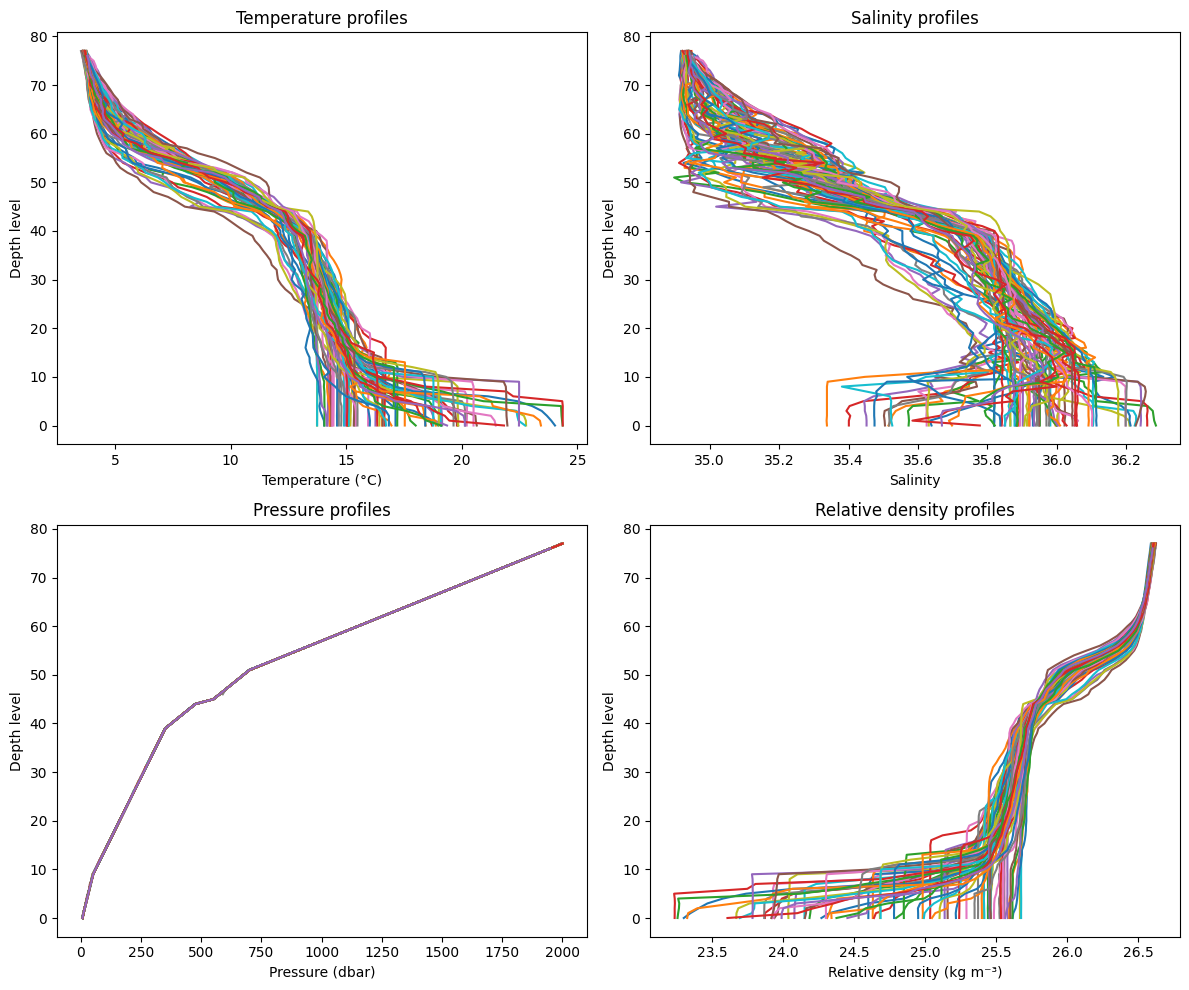

In [49]:
import matplotlib.pyplot as plt

# prepare the graph's place
fig, axes = plt.subplots(2, 2, figsize = (12, 10))

# Graph 1 (up left): plot temperature
axes[0, 0].plot(T, level)
axes[0, 0].set_xlabel("Temperature (°C)")
axes[0, 0].set_ylabel("Depth level")
axes[0, 0].set_title("Temperature profiles")

# Graph 2 (up right): plot salinity
axes[0, 1].plot(S, level)
axes[0, 1].set_xlabel("Salinity")
axes[0, 1].set_ylabel("Depth level")
axes[0, 1].set_title("Salinity profiles")

# Graph 3 (bottom left): plot pressure
axes[1, 0].plot(P, level)
axes[1, 0].set_xlabel("Pressure (dbar)")
axes[1, 0].set_ylabel("Depth level")
axes[1, 0].set_title("Pressure profiles")

# Graph 4 (bottom right): plot relative density
axes[1, 1].plot(relative_density, level)
axes[1, 1].set_xlabel("Relative density (kg m⁻³)")
axes[1, 1].set_ylabel("Depth level")
axes[1, 1].set_title("Relative density profiles")

plt.tight_layout()
plt.show()


- `plt.subplots(2, 2)` : crée 2 rangées et 2 colonnes.

- `axes[0, 0]` : graphique en haut à gauche.

- `axes[0, 1]` : graphique en haut à droite.

- `axes[1, 0]` : graphique en bas à gauche.

- `axes[1, 1]` : graphique en bas à droite.

- `figsize=(12, 10)` : règle la taille de la figure.

Pour aller plus loin et pour une meilleure visuallisation/interprétation du graohe, j'aurais pu aussi inverser l'axe des y, le mettre dans l'autre sens, pour faire comme si c'était une coupe de l'océan avec la profondeur qui diminue à force qu'on descende dans l'océan:


    `for ax in axes.flat:`

          `ax.invert_yaxis()`

          `ax.grid()`

  où `axes.flat` permet d'appliquer les mêmes réglages aux quatre graphiques.


**Step 10.** Now plot only the *mean* profile of each variable, with the standard deviation as
error bars.

Use the NaN-aware mean and standard deviation from Step 6, and draw them with `plt.errorbar`.
Because the variable is on the *x*-axis, the spread is a *horizontal* error bar — the keyword is
`xerr`, not `yerr`.

<img src="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/part-I/_static/1.3-target-argo-mean-profiles.png" alt="A single mean salinity profile against depth level with horizontal error bars at each level" width="500">

<em>The salinity panel again, reduced from 75 profiles to one line and its spread.</em>


In a comment, say what the width of the error bars tells you about how much the profiles disagree
near the surface compared with at depth.

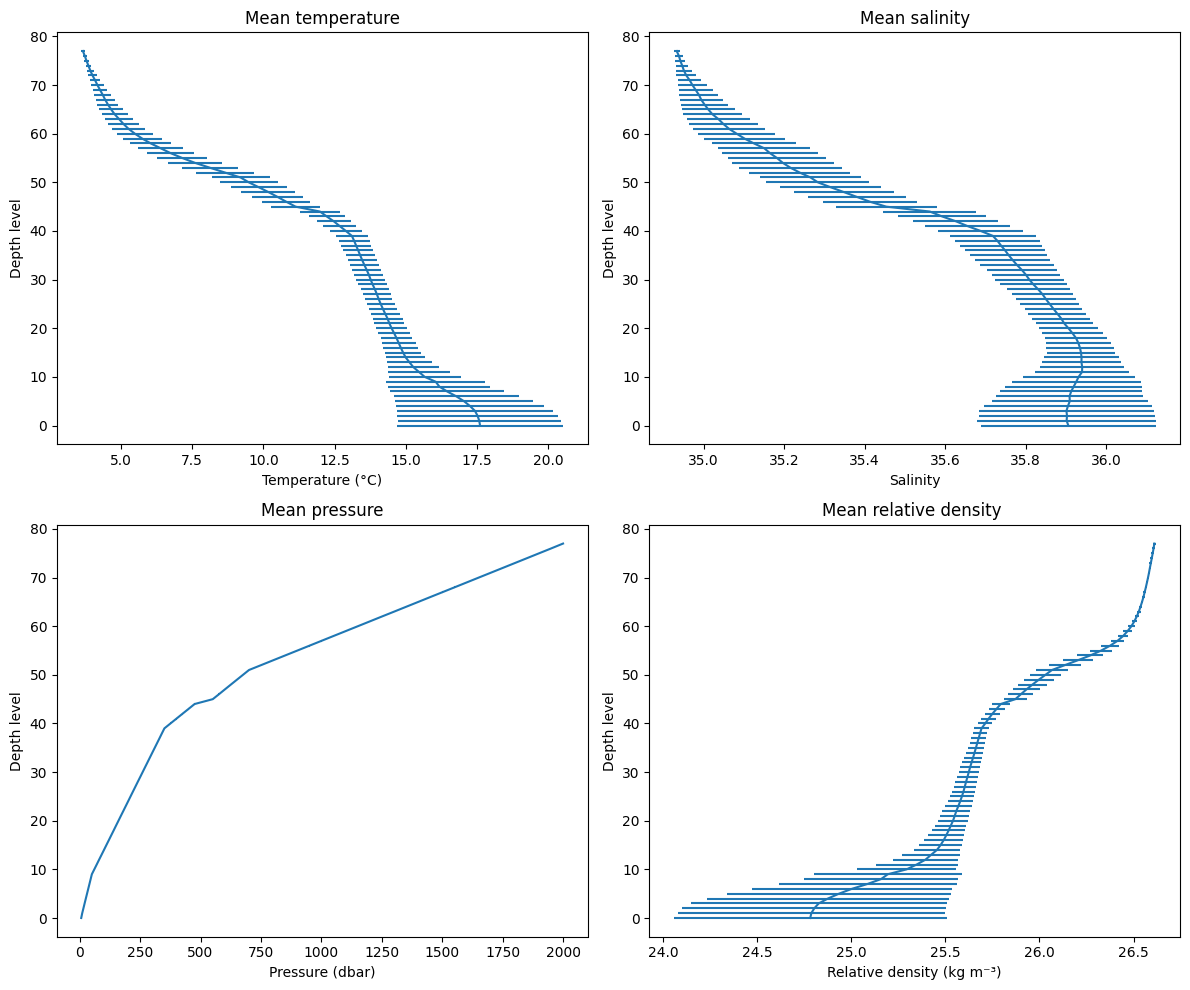

In [52]:
# Your solution here
# Hint: plt.errorbar(mean_S, level, xerr=std_S)
# Hint: use the nan-aware versions from Step 6, or every bar will be missing

import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize = (12, 10))

# Graph 1 (up left): plot mean temperature
axes[0, 0].errorbar(mean_T, level, xerr = std_T)
axes[0, 0].set_xlabel("Temperature (°C)")
axes[0, 0].set_ylabel("Depth level")
axes[0, 0].set_title("Mean temperature")

# Graph 2 (up right): plot salinity
axes[0, 1].errorbar(mean_S, level, xerr = std_S)
axes[0, 1].set_xlabel("Salinity")
axes[0, 1].set_ylabel("Depth level")
axes[0, 1].set_title("Mean salinity")

# Graph 3 (bottom left): plot pressure
axes[1, 0].errorbar(mean_P, level, xerr = std_P)
axes[1, 0].set_xlabel("Pressure (dbar)")
axes[1, 0].set_ylabel("Depth level")
axes[1, 0].set_title("Mean pressure")

# Graph 4 (bottom right): plot relative density
axes[1, 1].errorbar(mean_relative_density, level, xerr = std_relative_density)
axes[1, 1].set_xlabel("Relative density (kg m⁻³)")
axes[1, 1].set_ylabel("Depth level")
axes[1, 1].set_title("Mean relative density ")

plt.tight_layout()
plt.show()


Wider error bars mean greater disagreement between profiles.

- `xerr=std_T` adds horizontal error bars showing one standard deviation.

**Step 11.** Scatter the profiles' longitudes against their latitudes.

One point per profile. Label both axes and give it a title, and set the marker size with `s=` so
the points are readable. Then print the first three entries of `date` and the last one.

In a comment, say what the dates and the shape of the cloud tell you about how this set of
profiles was collected, and by how many floats.

['2012-07-13T22:33:06.019200000' '2012-07-23T22:54:59.990400000'
 '2012-08-02T22:55:52.003200000']
2014-07-24T03:02:33.014400000


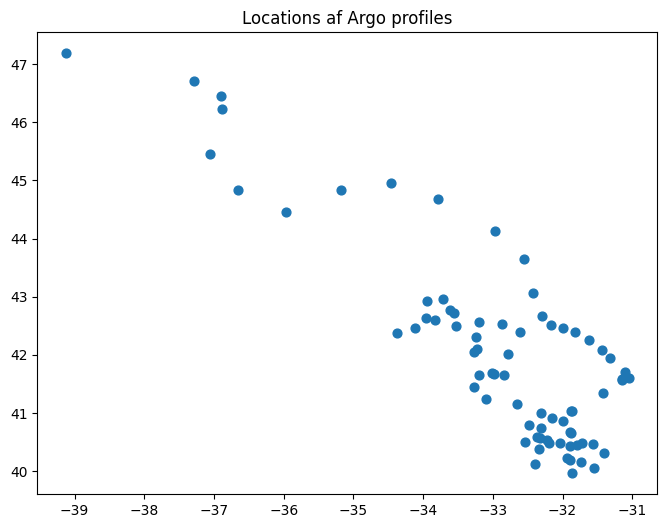

In [53]:
# Your solution here
# Hint: plt.scatter(lon, lat)
# Hint: lon and lat have one entry per profile, not per level
# Hint: look at the spacing between consecutive dates

import matplotlib.pyplot as plt

plt.figure(figsize = (8, 6))
plt.scatter(lon, lat, s = 40)
plt.xlabel = ("Longitude")
plt.ylabel = ("Latitude")
plt.title("Locations af Argo profiles")
plt.grid
plt.show

print(date[:3])
print(date[-1])

The dates show how frequently the profiles were collected. The spatial pattern of the points helps indicate how many floats collected them.

**ℹ️ What you just did**

You loaded a real oceanographic dataset, worked out its structure from the array shapes alone,
rebuilt a coordinate axis and verified it, evaluated a published equation of state as one
vectorised expression over 5,850 measurements (78 depth levels by 75 profiles), reduced along the
right axis, counted the missing values and switched to NaN-aware statistics, and saved a derived
product.

None of the computation needed a loop over the data. In the next subchapter `xarray` attaches the
names (depth, profile, latitude) to the axes you have been tracking by hand, and `matplotlib` gets
its full treatment, including the line, error-bar and scatter plots you drew here.